# Day 18: Cohort Retention Analysis
Building a cohort retention matrix with heatmap visualization.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('../Data/Processed/cleaned_sales.csv')
df['order_date'] = pd.to_datetime(df['order_date'])

## Define Cohorts

In [2]:
df['order_month'] = df['order_date'].dt.to_period('M')
df['cohort_month'] = df.groupby('customer_name')['order_date'].transform('min').dt.to_period('M')
df['cohort_index'] = (df['order_month'].dt.year - df['cohort_month'].dt.year) * 12 + (df['order_month'].dt.month - df['cohort_month'].dt.month) + 1

## Build Retention Matrix

In [3]:
cohort_data = df.groupby(['cohort_month', 'cohort_index'])['customer_name'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_name')
cohort_size = cohort_pivot.iloc[:,0]
retention = cohort_pivot.divide(cohort_size, axis=0)

## Heatmap Visualization

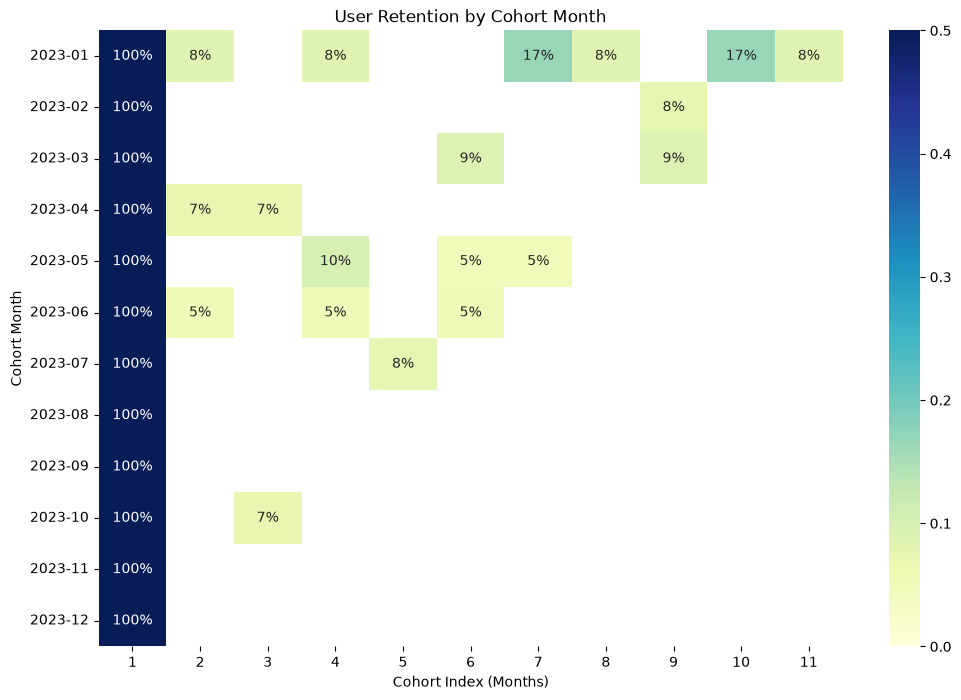

In [4]:
plt.figure(figsize=(12, 8))
plt.title('User Retention by Cohort Month')
sns.heatmap(retention, annot=True, fmt='.0%', cmap='YlGnBu', vmin=0.0, vmax=0.5)
plt.ylabel('Cohort Month')
plt.xlabel('Cohort Index (Months)')
plt.show()